# Setup

In [54]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('/Users/ccnlab/Development/dl4rl/')

import matplotlib.pyplot as plt
import seaborn as sns
import os
import utils.noisy_rl_utils as h
from typing import Hashable
from pandas.core.frame import DataFrame
import numpy as np
from scipy import special
import pandas as pd

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
# --- Experiment settings ---
experiment                 = 3
n_trials_per_block         = {0: 56, 1: 56, 2: 96, 3: 56}[experiment]
n_blocks                   = {0: 16, 1: 8, 2: 8, 3: 16}[experiment]
T                          = n_trials_per_block * n_blocks
n_agents_train             = 500
n_agents_test              = 500
n_agents                   = n_agents_train + n_agents_test
# --- Model settings ---
apply_rep_bias             = 1
apply_weber                = 1
apply_observational_noise  = 1
apply_counterfactual_learn = 1

model_name = "noisy_rl"
assert model_name in ["noisy_rl", "noiseless_rl"], "Invalid model name. Choose 'noisy_rl' or 'noiseless_rl'."
sim_fun = eval(f"h.simulate_{model_name}")
if model_name == "noisy_rl":
    has_epsilon = True

# Simulate

In [ ]:
# --- Parameters ---
alpha_c = np.random.uniform(0.05, 0.7, size=n_agents)
alpha_u = (
    np.random.uniform(0.05, 0.5, size=n_agents)
    if apply_counterfactual_learn
    else np.zeros(n_agents)
)
beta = np.random.uniform(35.0, 35.0, size=n_agents)
epsilon = (
    np.random.uniform(0.01, 1.0, size=n_agents) if has_epsilon else np.zeros(n_agents)
)
rep_bias = (
    np.random.uniform(-0.25, 0.5, size=n_agents)
    if apply_rep_bias
    else np.zeros(n_agents)
)
param_sets = np.column_stack((alpha_c, alpha_u, beta, epsilon, rep_bias))

In [ ]:
max_workers = 4
sim_df = h.simulate_agents(
    model_name, param_sets, experiment, n_blocks, n_trials_per_block, len(param_sets), 
    apply_rep_bias, apply_weber, apply_observational_noise, apply_counterfactual_learn, 
    max_workers=max_workers
)

# MI

In [30]:
param_keys = ["alpha_c", "alpha_u", "rep_bias"]
for param_key in param_keys:
    num_bins = 3
    beta_min = sim_df[param_key].min()
    beta_max = sim_df[param_key].max()
    beta_bins = np.linspace(beta_min, beta_max, num_bins + 1)
    sim_df[f"{param_key}_bin"] = pd.cut(
        sim_df[param_key], bins=beta_bins, labels=["Low", "Medium", "High"], include_lowest=True
    )

/var/folders/6y/khb9drcn0p373bwf72szrzvm0000gn/T/ipykernel_52140/1049275001.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sim_df.groupby(f"{param_key}_bin")
/Users/ccnlab/Development/dl4rl/utils/noisy_rl_utils.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  from functools import partial
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
/Users/ccnlab/Development/dl4rl/utils/noisy_rl_utils.py:5: Futu

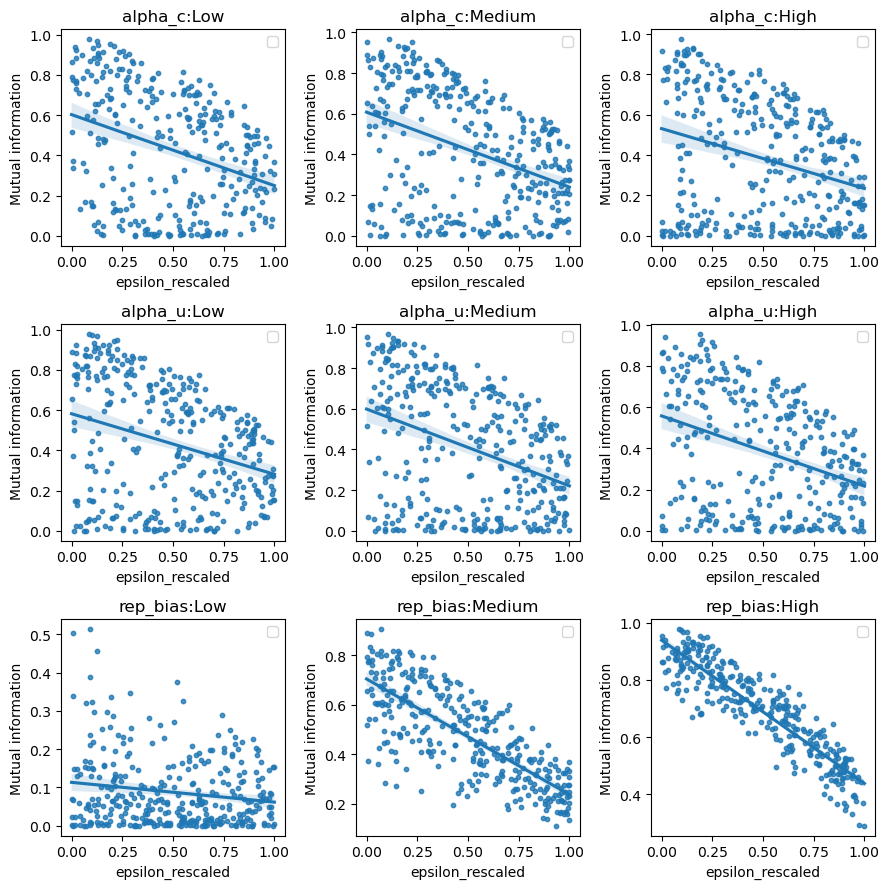

In [31]:
fig, axes = plt.subplots(nrows=len(param_keys), ncols=3, figsize=(3 * 3, 3*len(param_keys)))
for ri, param_key in enumerate(param_keys):
    for i, (bb, df) in enumerate[tuple[Hashable, DataFrame]](
        sim_df.groupby(f"{param_key}_bin")
    ):
        _, ax, plot_df = h.plot_mi_vs_params(df, "epsilon", fig=fig, ax=axes[ri, i])
        ax.set_title(f"{param_key}:{bb}")

fig.tight_layout()

/var/folders/6y/khb9drcn0p373bwf72szrzvm0000gn/T/ipykernel_52140/2034667557.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sim_df.groupby(f"{param_key}_bin")


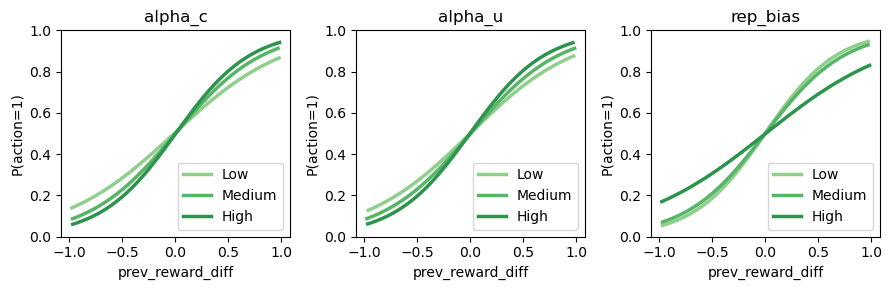

In [46]:
xvar = "prev_reward_diff"
yvar = "action"
palette = sns.color_palette("Greens")[2:]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(3 * 3, 3))
for ri, param_key in enumerate(param_keys):
    ax = axes[ri]
    for i, (bb, df) in enumerate[tuple[Hashable, DataFrame]](
        sim_df.groupby(f"{param_key}_bin")
    ):
        # We use a label here so the legend can find the "artist"
        ax = sns.regplot(
            data=df,
            x=xvar,
            y=yvar,
            logistic=True,
            scatter=False,
            ci=None,
            line_kws={"color": palette[i], "linewidth": 2.5},
            ax=ax,
            label=bb,
        )
    ax.legend(title="", loc="lower right")
    ax.set_title(f"{param_key}")
    ax.set_ylabel("P(action=1)")
    ax.set_ylim(0, 1)

fig.tight_layout()

In [62]:
import pandas as pd
from pandas._config.config import register_option, is_bool

try:
    pd.get_option("mode.use_inf_as_null")
except pd.errors.OptionError:
    register_option("mode.use_inf_as_null", False, validator=is_bool)

/Users/ccnlab/miniconda3/envs/dl4rl-k3/lib/python3.12/site-packages/seaborn/_core.py:989: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_data = data.groupby(
/Users/ccnlab/miniconda3/envs/dl4rl-k3/lib/python3.12/site-packages/seaborn/_core.py:1007: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Users/ccnlab/miniconda3/envs/dl4rl-k3/lib/python3.12/site-packages/seaborn/_core.py:1007: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grou

(<Figure size 900x300 with 3 Axes>,
 array([<Axes: title={'center': 'alpha_c_bin= Low'}, xlabel='Trials since reward crossover', ylabel='P(choose new optimal)'>,
        <Axes: title={'center': 'alpha_c_bin= Medium'}, xlabel='Trials since reward crossover', ylabel='optimal_choice'>,
        <Axes: title={'center': 'alpha_c_bin= High'}, xlabel='Trials since reward crossover', ylabel='optimal_choice'>],
       dtype=object))

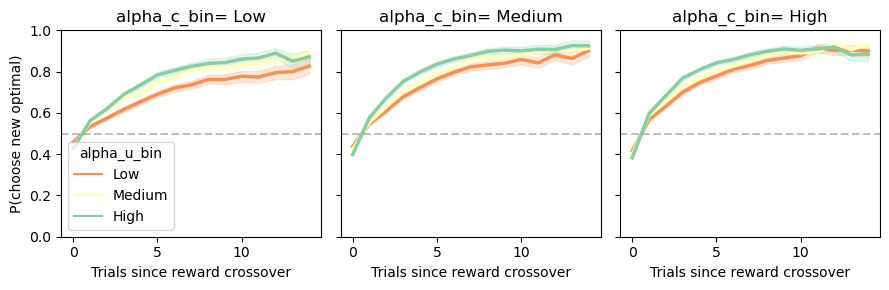

In [65]:
h.plot_switch_adaptation(sim_df, 'alpha_c_bin', 'alpha_u_bin')